# DAY6 실습 02 — 단순회귀 : 잔차 진단과 기울기 검정

In [ ]:
%pip install -q koreanize-matplotlib statsmodels

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan

In [ ]:
import os

from google.colab import drive

drive.mount("/content/drive")
data_folder = "/content/drive/MyDrive/HD-AI/data"
csv_path = os.path.join(data_folder, "ai4i2020.csv")

df = pd.read_csv(csv_path)

data = df.copy()

Mounted at /content/drive


## 데이터와 질문

| 데이터 파일 | 출처 | 한 행 | 쓰는 곳 |
|---|---|---|---|
| `ai4i2020.csv` | UCI Machine Learning Repository - [AI4I 2020 Predictive Maintenance Dataset](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset) | 운전 기록 1건 (10,000건) |
| `auto_mpg.csv` | UCI Machine Learning Repository - [Auto MPG](https://archive.ics.uci.edu/dataset/9/auto+mpg) (CC BY 4.0) | 자동차 1대 (398대) |

| AI4I 바꾼 이름 | 뜻 | 단위 |
|---|---|---|
| `air_temperature_k` | 공기온도 | K (켈빈) |
| `process_temperature_k` | 공정온도 | K |

| 자동차 열 이름 | 뜻 | 단위 |
|---|---|---|
| `mpg` | 연비. 클수록 연료를 덜 쓴다 | 마일/갤런 |
| `weight` | 무게 | 파운드 |
| `acceleration` | 가속시간 : 시속 0 -> 60마일에 걸리는 시간. 클수록 느린 차 | 초 |
| `cylinders` | 실린더(기통) 수 | 개 |
| `origin` | 생산지역 (usa · europe · japan) | 없음 |

**질문** : 구한 회귀식을 믿고 써도 되는가? 모집단에서도 선형 관계가 있다고 말할 수 있는가? 어떤 x 값까지 예측에 쓸 수 있는가?

**실습 전제** :  관측끼리 서로 독립이라고 가정한다.

In [ ]:
raw = data.rename(columns={"Air temperature [K]": "air_temperature_k",       # 공기온도 (K)
                           "Process temperature [K]": "process_temperature_k",  # 공정온도 (K)
                           "Rotational speed [rpm]": "rotational_speed_rpm",    # 회전수 (rpm)
                           "Torque [Nm]": "torque_nm",                          # 토크 (Nm)
                           "Tool wear [min]": "tool_wear_min"})                 # 공구 마모시간 (분)

numeric_cols = ["air_temperature_k", "process_temperature_k", "rotational_speed_rpm", "torque_nm", "tool_wear_min"]
print("행·열:", raw.shape)
print(raw[numeric_cols].isna().sum())

행·열: (10000, 14)
air_temperature_k        0
process_temperature_k    0
rotational_speed_rpm     0
torque_nm                0
tool_wear_min            0
dtype: int64


In [ ]:
# 자동차 자료도 같은 폴더에서 읽는다
cars = pd.read_csv(os.path.join(data_folder, "auto_mpg.csv"))
print("자동차 행·열:", cars.shape)

자동차 행·열: (398, 9)


In [ ]:
# 공기온도(x) -> 공정온도(y) 회귀식과 예측값 · 잔차를 구해 둔다
temp_pair = raw[["air_temperature_k", "process_temperature_k"]].dropna()
x = temp_pair["air_temperature_k"]
y = temp_pair["process_temperature_k"]
temp_reg = stats.linregress(x, y)
temp_pred = temp_reg.intercept + temp_reg.slope * x       # 예측값
temp_resid = y - temp_pred                                 # 잔차 = 실제값 − 예측값
print("회귀식 : 공정온도 예측값 =", round(temp_reg.intercept, 3), "+", round(temp_reg.slope, 4), "× 공기온도")

회귀식 : 공정온도 예측값 = 115.041 + 0.6499 × 공기온도


## 1. 잔차 그래프 : 직선이 맞는지 확인한다

관계가 휘어 있어도 직선이 하나 나오므로, 직선이 관계를 제대로 잡았는지 따로 확인해야 한다.

**잔차 그래프**는 가로축에 예측값, 세로축에 잔차를 놓은 산점도다. 직선이 관계를 잘 잡았으면 잔차에는 더 이상 규칙이 남지 않는다.

| 잔차 그래프 모양 | 뜻 | 대응 |
|---|---|---|
| 0 위아래로 고르게 흩어짐 | 직선이 관계를 잘 잡았다 | 그대로 쓴다 |
| 곡선 모양 (구간마다 + 또는 −로 몰림) | 관계가 직선이 아니다 | 선형 회귀를 그대로 쓰지 않는다. 변수 변환 또는 x² 항 추가 등 곡선을 표현하는 모형을 검토한다 |
| 깔때기 모양 (값이 클수록 퍼짐이 커짐) | 오차의 분산이 일정하지 않다 (등분산성 위배) | 원인을 확인하고, 종속변수 변환(로그 등)을 검토한다 |
| 몇 무리로 나뉜 모양 | 빠진 변수(집단 등)가 있을 수 있다 | 원인을 확인하고, 집단이면 나눠 다시 본다 |

| 함수 | 기능 |
|---|---|
| `plt.axhline(0, color="red", linestyle="--")` | 높이 0 에 가로 기준선을 긋는다. linestyle="--" 는 점선 |

공식 문서 : [NIST e-Handbook : How can I tell if a model fits my data?](https://www.itl.nist.gov/div898/handbook/pmd/section4/pmd44.htm) · [matplotlib.pyplot.axhline](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.axhline.html)

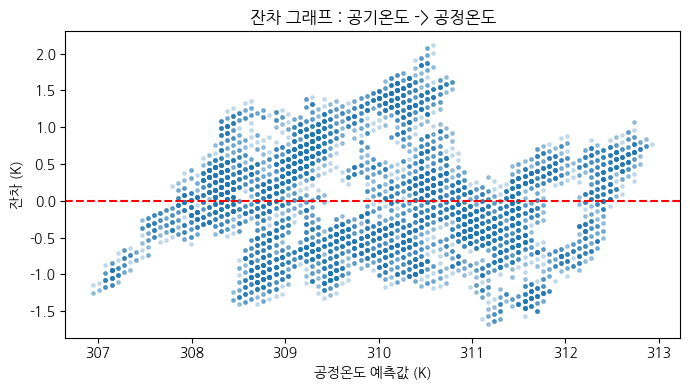

In [ ]:
# [예제 1] 공기온도 -> 공정온도 회귀의 잔차 그래프
plt.figure(figsize=(7, 4))
plt.scatter(temp_pred, temp_resid, s=6, alpha=0.2)       # 가로 : 예측값, 세로 : 잔차
plt.axhline(0, color="red", linestyle="--")              # 잔차 0 기준선
plt.xlabel("공정온도 예측값 (K)")
plt.ylabel("잔차 (K)")
plt.title("잔차 그래프 : 공기온도 -> 공정온도")
plt.tight_layout()
plt.show()

# [결과]
# - 전체로 보면 잔차가 0 위아래에 걸쳐 있고, 뚜렷한 U자형이나 깔때기 모양은 없다
# - 다만 점들이 고르게 흩어지지 않고 몇 무리로 나뉘어 있다 -> 회귀선이 설명하지 못한 다른 요인이 있는지 살펴볼 필요가 있다


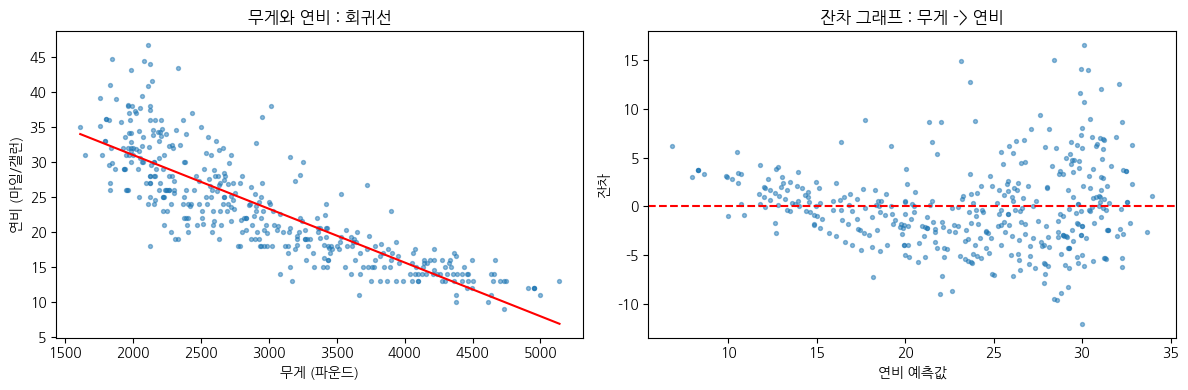

R²: 0.692
기울기: -0.00768 mpg


In [ ]:
# [예제 2] 무게 -> 연비 회귀 : 산점도와 회귀선, 잔차 그래프를 나란히 본다
# 자동차 데이터에서 무게(weight)와 연비(mpg) 열을 선택하고 결측값 제거
weight_pair = cars[["weight", "mpg"]].dropna()

wx = weight_pair["weight"]  # 독립변수 X: 자동차 무게
wy = weight_pair["mpg"]     # 종속변수 Y: 자동차 연비

# 단순선형회귀 분석으로 기울기와 절편 계산
weight_reg = stats.linregress(wx, wy)

# 회귀식(예측값 = 절편 + 기울기 × 무게)을 이용해 연비 예측
weight_pred = weight_reg.intercept + weight_reg.slope * wx

# 잔차 계산: 실제 연비 − 예측 연비
weight_resid = wy - weight_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4))          # 1행 2열 서브플롯 생성 (전체 크기: 가로 12, 세로 4인치)
line_wx = wx.sort_values()                                # 회귀선을 매끄럽게 잇기 위해 무게(wx)를 오름차순 정렬
axes[0].scatter(wx, wy, s=8, alpha=0.5)                   # 왼쪽 [0]: 무게-연비 산점도 (점 크기 8, 반투명도 0.5)
axes[0].plot(line_wx, weight_reg.intercept + weight_reg.slope * line_wx, color="red")  #  회귀선 그리기
axes[0].set(title="무게와 연비 : 회귀선", xlabel="무게 (파운드)", ylabel="연비 (마일/갤런)")  # 왼쪽 그래프 제목 및 축 라벨 설정

axes[1].scatter(weight_pred, weight_resid, s=8, alpha=0.5)  # 오른쪽 [1]: 잔차 그래프 (가로: 예측 연비, 세로: 잔차)
axes[1].axhline(0, color="red", linestyle="--")           # 잔차 기준선 y=0을 빨간 점선(--)으로 표시
axes[1].set(title="잔차 그래프 : 무게 -> 연비", xlabel="연비 예측값", ylabel="잔차")  # 오른쪽 그래프 제목 및 축 라벨 설정

plt.tight_layout()                                        # 서브플롯 간 제목·라벨이 겹치지 않도록 여백 자동 조절
plt.show()                                                # 두 그래프 화면에 출력
print("R²:", round(weight_reg.rvalue ** 2, 3))            # 결정계수(상관계수 r의 제곱)를 소수점 3째 자리까지 출력
print("기울기:", round(weight_reg.slope, 5), "mpg/파운드")  # 1파운드당 기울기(소수점 5째 자리)

# [결과]
# - 산점도 : 점들이 휘어 있는데 직선을 그었다. 가벼운 쪽과 무거운 쪽 끝에서 점들이 직선보다 위에 있다
# - 잔차 그래프 : 가운데(예측값 15 ~ 25)는 잔차가 − 쪽으로, 양 끝은 + 쪽으로 몰린 완만한 U자 모양이다 -> 관계가 직선이 아니다
#   오른쪽(가벼운 차)으로 갈수록 퍼짐도 커진다(깔때기 모양)
# - 기울기 −0.00768
# - R² 가 0.692 로 낮지 않지만, 직선이 관계를 제대로 잡지 못했다. R² 만 보고 선형 회귀를 믿지 않는다

## 2. 단순회귀의 가정

기울기 검정의 p값과 신뢰구간은 오차에 대한 몇 가지 가정 아래에서 계산된다. 회귀모형의 가정이 충족되지 않으면 기울기의 p값 · 신뢰구간이 부정확해지거나 예측의 신뢰성이 떨어질 수 있다. 오차(모집단 회귀선과의 차이)는 볼 수 없으므로, 계산할 수 있는 **잔차**로 대신 확인한다.

| 가정 | 정의 | 확인 방법  |
|---|---|---|
| 선형성 | x와 y의 평균적인 관계가 직선이다 | 산점도 · 잔차 그래프에 U자형 등 곡선 패턴이 있는지 확인 |
| 독립성 | 각 관측의 오차는 서로 독립이다 (관련이 없다) | 자료를 모은 방식과, 측정 순서에 따라 잔차에 일정한 패턴이 있는지 확인 |
| 정규성 | 오차가 정규분포를 따른다 | **잔차**의 히스토그램 · Q-Q 플롯 · 정규성 검정 (x · y가 아니라 잔차를 본다) |
| 등분산성 | x가 달라져도 오차의 분산이 일정하다 | 잔차 그래프 · Breusch–Pagan 검정 |

- 정규성은 잔차가 5,000개 이하면 `stats.shapiro`로 검정한다. 5,000개를 초과하면 Shapiro 검정의 p값이 부정확할 수 있어 `stats.normaltest`로 검정한다. 검정 결과는 히스토그램 · Q-Q 플롯과 함께 확인한다
- 표본이 크면 정규분포와의 작은 차이도 검정에서 기각된다. 검정 결과와 그림을 함께 보고 판단한다

공식 문서 : [scipy.stats.probplot](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.probplot.html) · [scipy.stats.shapiro](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html) · [scipy.stats.normaltest](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.normaltest.html) · [NIST e-Handbook : 회귀의 기본 가정](https://www.itl.nist.gov/div898/handbook/pmd/section2/pmd21.htm)

잔차 개수: 10000
normaltest p값: 2.5309721994225788e-74
p < 0.05 ? True


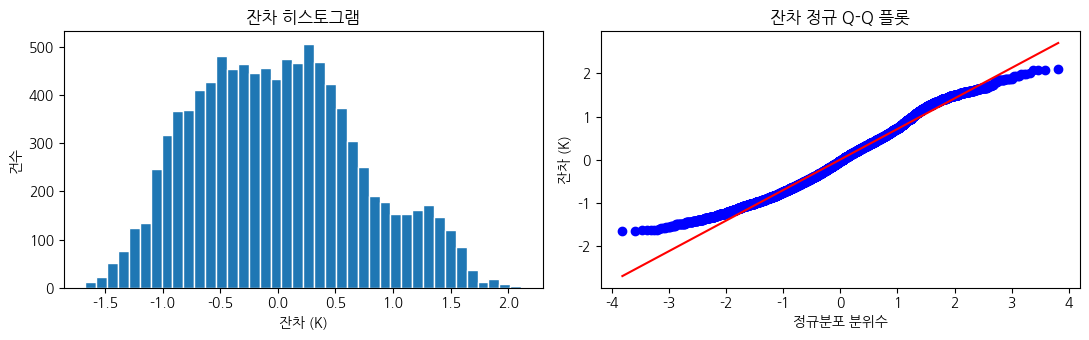

In [ ]:
# [예제] 공기온도 -> 공정온도 회귀의 잔차 정규성 : normaltest · 히스토그램 · Q-Q 플롯
# 귀무가설(H₀): 잔차가 정규분포를 따른다.
# 대립가설(H₁): 잔차가 정규분포를 따르지 않는다.

print("잔차 개수:", len(temp_resid))

norm_res = stats.normaltest(temp_resid)   # 잔차가 5,000개를 넘어 Shapiro 대신 쓴다
print("normaltest p값:", norm_res.pvalue)
print("p < 0.05 ?", norm_res.pvalue < 0.05)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(temp_resid, bins=40, edgecolor="white")
axes[0].set(title="잔차 히스토그램", xlabel="잔차 (K)", ylabel="건수")
stats.probplot(temp_resid, dist="norm", plot=axes[1])    # probplot : 점이 직선을 따라가면 정규분포에 가깝다
axes[1].set(title="잔차 정규 Q-Q 플롯", xlabel="정규분포 분위수", ylabel="잔차 (K)")
plt.tight_layout()
plt.show()

# [결과]
# - 선형성 : 산점도와 잔차 그래프에서 뚜렷한 곡선 패턴이 있는지 확인한다.
#   잔차에 뚜렷한 곡선 패턴이 보이지 않으면 직선 관계에 큰 문제가 없는지 살펴볼 수 있다.
# - 정규성 검정 : normaltest p < 0.001 < 0.05 이므로 귀무가설을 기각한다. 잔차 분포는 정규분포와 차이가 있다
# - 정규성 그림 : 표본이 10,000개로 크면 작은 차이도 기각되므로 그림에서 벗어난 정도를 함께 본다.
#   히스토그램은 0 을 중심으로 모여 있고, Q-Q 점은 가운데에서 직선을 따르다가 양 끝에서 벗어난다
#   검정 결과와 그림에서 본 것을 함께 적고, p값을 해석할 때 한계로 둔다
# - 독립성 : 이 실습에서는 관측끼리 독립이라고 가정했다.

### 등분산성 검정 : Breusch–Pagan 검정

잔차 그래프에서는 깔때기 모양처럼 퍼짐이 달라지는지를 그림으로 확인했다. **Breusch–Pagan 검정**은 x가 달라질 때 오차의 분산도 달라지는지를 검정한다.

- 귀무가설(H₀): 공기온도에 따라 오차의 분산이 달라지지 않는다. (등분산)
- 대립가설(H₁): 공기온도에 따라 오차의 분산이 달라진다. (이분산)

| 검정 결과 | 통계적 결론 | 사실적 결론 |
|---|---|---|
| p < 0.05 | 귀무가설을 기각한다 | 오차의 분산이 일정하지 않다 |
| p ≥ 0.05 | 귀무가설을 기각하지 못한다 | 오차의 분산이 달라진다는 근거가 부족하다 |

| 함수 | 기능 |
|---|---|
| `sm.add_constant(x)` | x에 절편에 해당하는 상수항 열을 추가한다. Breusch–Pagan 검정은 내부에서 회귀분석을 하므로 상수항이 필요하다 |
| `het_breuschpagan(잔차, 상수항을 추가한 x)` | 잔차와 독립변수로 등분산성을 검정한다. 돌려주는 값 중 두 번째가 p값이다 |

- 이 p값은 등분산성 검정의 p값이다. 기울기 검정의 p값과 다른 값이다
- p ≥ 0.05가 등분산성을 증명하는 것은 아니다. 표본이 크면 분산의 작은 차이도 기각되므로, 검정 결과는 잔차 그래프와 함께 확인한다

공식 문서 : [statsmodels het_breuschpagan](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.het_breuschpagan.html) · [statsmodels add_constant](https://www.statsmodels.org/stable/generated/statsmodels.tools.tools.add_constant.html)

In [ ]:
# [예제] 공기온도 -> 공정온도 회귀의 등분산성 검정 : Breusch–Pagan 검정
# 귀무가설(H₀): 공기온도에 따라 오차의 분산이 달라지지 않는다. (등분산)
# 대립가설(H₁): 공기온도에 따라 오차의 분산이 달라진다. (이분산)
# 앞에서 구한 x(공기온도)와 temp_resid(잔차)를 사용

X_bp = sm.add_constant(x)                           # x에 상수항(절편) 열을 추가한다

bp_lm, bp_p, bp_f, bp_f_p = het_breuschpagan(temp_resid, X_bp)

# LM 검정: 통계량과 p값
print("LM p값:", round(bp_p, 4))

# F 검정: 통계량과 p값
print("F p값:", round(bp_f_p, 4))

# [결과]
# - 통계적 결론 : p = 0.0194 < 0.05 이므로 귀무가설을 기각한다
# - 사실적 결론 : 공기온도에 따라 오차의 분산이 달라진다
# - 검정과 그림 : 표본이 10,000개로 크면 분산의 작은 차이도 기각되므로 잔차 그래프를 함께 본다.
#   앞의 잔차 그래프에 깔때기 모양은 없으나, 구간에 따라 잔차의 퍼짐이 다르다


# - het_breuschpagan  값  : LM 통계량, LM p값, F 통계량, F p값.
#   LM 검정은 잔차의 제곱을 x로 다시 회귀한 결과로 계산하고, F 검정은 같은 회귀의 F통계량으로 계산한다. 이 자료는 두 p값이 모두 0.0194 다
# 공식문서
# x에 상수항이 포함되어 있다고 가정합니다(자유도 계산 및 R² 계산용).
# 그린은 LM 검정에 대한 일반적인 설명에서 이 검정이 표본 크기가 작거나 중간 정도일 때 결과의 유의성을 과장한다고 언급합니다.
# 이러한 경우에는 F 통계량이 더 적합합니다.
# Assumes x contains constant (for counting dof and calculation of R^2). In the general description of LM test,
# Greene mentions that this test exaggerates the significance of results in small or moderately large samples.
# In this case the F-statistic is preferable.

LM p값: 0.0194
F p값: 0.0194


## 3. 기울기 검정 : 모집단에서도 선형 관계가 있는가

표본에서 구한 기울기 0.65는 표본을 다시 뽑으면 달라진다. 모집단의 기울기가 사실은 0인데 우연히 0.65가 나온 것은 아닌지 확인해야 "선형 관계가 있다"고 말할 수 있다.

표본 기울기 b₁은 모집단 기울기 β₁을 추정하는 값이다.

| 구분 | 내용 |
|---|---|
| 검정 목적 | 모집단에서도 두 변수 사이에 선형 관계가 있다고 볼 통계적 근거가 있는지 확인한다 |
| 가설 설정 | 귀무가설(H₀): 모집단 회귀기울기는 0이다. (β₁ = 0)<br>대립가설(H₁): 모집단 회귀기울기는 0이 아니다. (β₁ ≠ 0) |
| 검정 방법 | 일표본 t검정과 같은 원리다. 추정한 기울기가 기준값 0과 다른지 표준오차를 이용해 판단한다.<br>t = (b₁ − 0) ÷ 기울기의 표준오차 |
| 결과 판단 | p < 0.05이면 귀무가설을 기각한다. 두 변수 사이에 유의한 선형 관계가 있다.<br>p ≥ 0.05이면 귀무가설을 기각하지 못한다. 선형 관계가 있다는 근거가 부족하다 |
| 해석 시 주의 | 1) 회귀모형의 가정을 확인한 뒤 p값을 해석한다.<br>2) 기울기의 크기와 신뢰구간을 함께 확인한다.<br>3) 유의하다는 것은 예측의 정확도나 인과를 뜻하지 않는다 |

가설을 먼저 세우고, 다음 네 단계로 분석한다.

| 단계 | 할 일 |
|---|---|
| 1) 선형성 확인 | 산점도가 직선 형태인지 확인한다. 곡선이면 선형 회귀를 그대로 쓰지 않는다 |
| 2) 회귀식 추정 | `linregress`로 절편과 기울기를 구하고, x의 관측 범위를 확인한다 |
| 3) 잔차로 가정 확인 | 잔차 그래프 · 정규성 검정 · 등분산성 검정 · 독립성 |
| 4) 검정 결과 해석 및 결론 | 통계적 결론 · 사실적 결론을 쓰고 회귀식, R², p값, 관측 범위, 한계를 함께 보고한다 |

| 함수 | 기능 |
|---|---|
| `결과.pvalue` | 귀무가설 "모집단 기울기는 0이다"에 대한 양측 p값 |
| `결과.stderr` | 추정한 기울기의 표준오차 |

단순회귀의 기울기 검정 p값은 같은 자료의 피어슨 상관계수 검정 p값과 같다. 둘 다 "선형 관계가 있는가"를 묻기 때문이다.

공식 문서 : [scipy.stats.linregress](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.linregress.html)

In [ ]:
# [예제] 공기온도 -> 공정온도의 기울기 검정
# 귀무가설(H₀): 모집단에서 공기온도와 공정온도 사이에 선형 관계가 없다. (β₁ = 0)
# 대립가설(H₁): 모집단에서 공기온도와 공정온도 사이에 선형 관계가 있다. (β₁ ≠ 0)
# 1) 선형성 · 2) 회귀식 · 3) 가정은 앞에서 확인했다 : 산점도가 직선 형태, 115.041 + 0.6499 × 공기온도,
#    잔차 그래프 · 정규성 검정 · 등분산성 검정 결과를 함께 판단, 독립성은 관측끼리 독립이라고 가정
# 4) 검정 결과 해석 및 결론
alpha = 0.05          # 유의수준 α, 양측

print("기울기:", round(temp_reg.slope, 4), "/ R²:", round(temp_reg.rvalue ** 2, 4))
print("기울기의 표준오차:", round(temp_reg.stderr, 4), "/ t:", round(temp_reg.slope / temp_reg.stderr, 1))   # t = (기울기 − 0) ÷ 표준오차
print("p값:", temp_reg.pvalue, "/ p < α ?", temp_reg.pvalue < alpha)   # 매우 작아 0.0 으로 표시된다. 보고할 때는 p < 0.001 로 적는다
print("피어슨 상관 검정 p값:", stats.pearsonr(x, y).pvalue)   # 같은 값이 나오는지 확인한다

# [결과]
# - n = 10,000, 기울기 0.6499, 표준오차 0.0036, t = 181.7, R² = 0.768, p < 0.001
# - 통계적 결론 : p < 0.001 이므로 유의수준 0.05에서 귀무가설을 기각한다
# - 사실적 결론 : 공기온도와 공정온도 사이에 유의한 양의 선형 관계가 있다.
#   공기온도가 1 K 높은 경우, 공정온도의 예측값은 약 0.65 K 높다
# - 한계 : 잔차의 정규성 및 등분산성 검정에서 가정 위반의 통계적 근거가 발견되었다.
#   p < 0.001 은 선형 관계가 있다는 근거이며, 예측이 정확하다거나 공기온도가 원인이라는 뜻은 아니다
# - 보고 : AI4I 운전 기록 10,000건에서 공정온도 예측값 = 115.041 + 0.6499 × 공기온도 (R² = 0.768, 기울기 검정 p < 0.001)이다.
#   공기온도 295.3 ~ 304.5 K 구간의 관찰자료이며, 관측끼리 독립이라고 가정한 계산이다.

기울기: 0.6499 / R²: 0.7676
기울기의 표준오차: 0.0036 / t: 181.7
p값: 0.0 / p < α ? True
피어슨 상관 검정 p값: 0.0


### [참고] OLS 결과표

같은 회귀 결과를 `statsmodels`의 OLS 결과표(`summary()`)로도 볼 수 있다. OLS(Ordinary Least Squares)는 최소제곱법으로 구한 회귀를 뜻한다.

결과표에서 확인할 항목은 다음과 같다. 그 밖의 항목은 이 과정에서 다루지 않는다.

| 결과표 항목 | 뜻 | 앞의 결과 |
|---|---|---|
| `coef` | 절편(const)과 기울기 | 115.041, 0.6499 |
| `std err` | 표준오차 | 기울기의 표준오차 0.004 |
| `t` | t = coef ÷ std err | 181.703 |
| `P>\|t\|` | 기울기 검정의 p값 | 0.000 (p < 0.001) |
| `[0.025  0.975]` | 95% 신뢰구간 | 기울기 0.643 ~ 0.657 |
| `R-squared` | 결정계수 R² | 0.768 |


공식 문서 : [statsmodels OLS](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLS.html)

In [ ]:
# [예제] 공기온도 -> 공정온도 회귀의 OLS 결과표
ols_fit = sm.OLS(y, sm.add_constant(x)).fit()       # 상수항을 추가한 x로 회귀식을 구한다
print(ols_fit.summary())


# Durbin–Watson(DW): 앞뒤 잔차가 서로 비슷하게 나타나는지 확인하는 지표
# 잔차의 자기상관: 앞의 잔차와 다음 잔차가 서로 관련되어 나타나는 현상

# DW ≈ 2 : 앞뒤 잔차 사이에 뚜렷한 관계가 없음
# DW ≈ 0 : 앞뒤 잔차가 비슷하게 나타나는 경향이 강함
# DW ≈ 4 : 앞뒤 잔차가 반대 방향으로 나타나는 경향이 강함

# 이번 결과 DW = 0.009
# → 앞뒤 잔차가 비슷하게 이어지는 경향이 강해 독립성에 문제가 있을 수 있음.

# AI4I 회귀분석에서 관측 순서상 연속된 잔차들이 서로 관련되어 있을 가능성이 크다.

                              OLS Regression Results                             
Dep. Variable:     process_temperature_k   R-squared:                       0.768
Model:                               OLS   Adj. R-squared:                  0.768
Method:                    Least Squares   F-statistic:                 3.302e+04
Date:                   Wed, 25 Nov 2026   Prob (F-statistic):               0.00
Time:                           04:47:12   Log-Likelihood:                -10839.
No. Observations:                  10000   AIC:                         2.168e+04
Df Residuals:                       9998   BIC:                         2.170e+04
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const   

### [결과 해석] 공기온도와 공정온도의 단순회귀분석

**회귀식과 기울기 검정**

- 회귀식 : **공정온도 예측값 = 115.041 + 0.6499 × 공기온도**
- 기울기 **0.6499** (95% 신뢰구간 0.643 ~ 0.657) : 공기온도가 1 K 높은 경우, 공정온도의 예측값은 약 0.65 K 높다
- 결정계수 **R² = 0.7676** : 공정온도 변동의 약 **76.8%**를 회귀모형이 설명한다
- 기울기 검정 **p < 0.001** : 단순선형회귀의 기울기 검정에서는 p < 0.001로 나타났다. 그러나 잔차 진단에서 정규성·등분산성 가정에 문제가 발견되고 자기상관도 의심되므로, 이 p값을 근거로 모집단에서도 선형 관계가 있다고 단정하기는 어렵다.
  

**결과해석**  

잔차의 정규성과 등분산성 검정에서 문제가 발견되었고, 독립성에도 문제가 있을 가능성이 나타났다.
따라서 회귀식은 현재 데이터의 관계를 설명하지만, 통계적 검정 결과를 해석하고 다른 데이터에 적용할 때는 주의가 필요하다.  

**잔차로 확인한 가정**

| 확인 항목 | 검정 결과 | 그림에서 본 것 |
|---|---|---|
| 선형성 (잔차 그래프) | 검정 없음 | 뚜렷한 U자형 곡선은 없다 |
| 남은 패턴 (잔차 그래프) | 검정 없음 | 잔차가 고르게 흩어지지 않고 몇 무리로 나뉘어 있다 |
| 정규성 (`normaltest`, 히스토그램, Q-Q 플롯) | p < 0.001, 귀무가설을 기각한다 | Q-Q 점이 가운데에서 직선을 따르고 양 끝에서 벗어난다 |
| 등분산성 (Breusch–Pagan, 잔차 그래프) | p = 0.0194, 귀무가설을 기각한다 | 깔때기 모양은 없으나 구간에 따라 잔차의 퍼짐이 다르다 |
| 독립성 | 자기상관이 확인됨 |  |



## 4. 예측과 관측 범위 : 보간과 외삽

회귀식에는 어떤 x든 넣을 수 있지만, 선형 관계는 **관측한 x 범위 안에서만** 확인한 것이다. 범위 밖에서도 같은 직선이 이어진다는 근거는 없다.

| 구분 | 뜻 | 예측여부 |
|---|---|---|
| **보간** | 관측 범위 안의 x로 예측한다 | 예측 할 수 있지만 예측 불확실성은 남는다 |
| **외삽** | 관측 범위 밖의 x로 예측한다 | 같은 관계가 이어진다는 근거가 없다. 그 구간의 실제 자료로 확인하기 전에는 쓰지 않는다 |

| 함수 | 기능 |
|---|---|
| `plt.axvspan(시작, 끝, alpha=0.1)` | 가로축의 한 구간을 색으로 칠한다. 관측 범위를 표시할 때 쓴다 |

공식 문서 : [matplotlib.pyplot.axvspan](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.axvspan.html)

관측 범위 : 공기온도 295.3 ~ 304.5 K
공기온도 300 K -> 공정온도 예측값 310.0 K / 관측 범위 안 ? True
공기온도 312 K -> 공정온도 예측값 317.8 K / 관측 범위 안 ? False


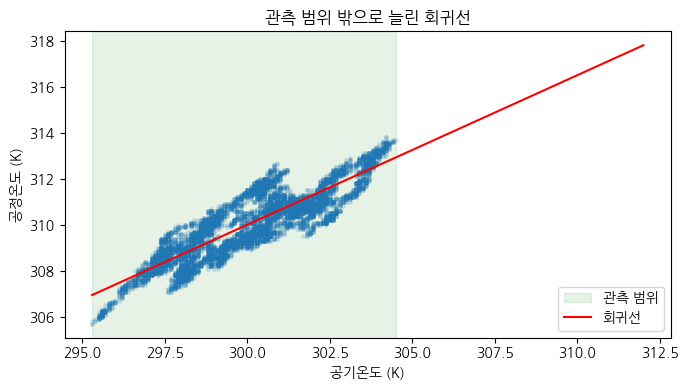

In [ ]:
# [예제] 공기온도 300 K(범위 안)와 312 K(범위 밖)의 예측값을 비교한다
print("관측 범위 : 공기온도", x.min(), "~", x.max(), "K")
for new_x in [300, 312]:
    new_pred = temp_reg.intercept + temp_reg.slope * new_x
    inside = x.min() <= new_x <= x.max()                  # 범위 안이면 True
    print("공기온도", new_x, "K -> 공정온도 예측값", round(new_pred, 2), "K / 관측 범위 안 ?", inside)

line_x = pd.Series([x.min(), 312])                         # 회귀선을 312 K 까지 늘려 그린다
plt.figure(figsize=(7, 4))
plt.axvspan(x.min(), x.max(), alpha=0.1, color="green", label="관측 범위")
plt.scatter(x, y, s=6, alpha=0.15)
plt.plot(line_x, temp_reg.intercept + temp_reg.slope * line_x, color="red", label="회귀선")
plt.xlabel("공기온도 (K)")
plt.ylabel("공정온도 (K)")
plt.title("관측 범위 밖으로 늘린 회귀선")
plt.legend()
plt.tight_layout()
plt.show()

# [결과]
# - 300 K : 관측 범위(295.3 ~ 304.5 K) 안이다 -> 예측값 310.00 K 를 쓸 수 있다 (보간)
# - 312 K : 범위 밖이다 -> 식으로는 317.80 K 가 계산되지만, 그 구간에도 같은 직선이 이어진다는 근거가 없어 그 구간의 실제 자료로 확인하기 전에는 쓰지 않는다 (외삽)
# - 회귀식을 보고할 때는 적용 범위를 반드시 함께 적는다

## 5. 문제 : 6기통 차의 무게로 가속시간 예측하기

6기통 차 84대의 무게와 가속시간은 피어슨 r = 0.599로 보통 정도의 양의 상관이다. 회귀식을 구하고, 가설을 세운 뒤 네 단계로 이 회귀식을 믿고 쓸 수 있는지 판단한다.

In [ ]:
# 문제 5-1) 목적 · 자료 확인과 회귀식
# 6기통 차(cylinders 가 6)만 골라 무게(x)로 가속시간(y)을 예측하는 회귀식을 구하시오. 대수와 무게의 관측 범위를 출력하고, 기울기를 100파운드 기준으로 해석하시오.



In [ ]:
# 문제 5-2) 산점도와 잔차 그래프
# 산점도에 회귀선을 그리고, 잔차 그래프를 그려 선형 회귀가 맞는지 판단하시오.



In [ ]:
# 문제 5-3) 조건 확인
# 잔차의 Shapiro-Wilk 정규성 검정 p값을 구하고(소수 셋째 자리까지), 독립성과 함께 조건을 판단하시오.
#   귀무가설(H₀): 잔차는 정규분포를 따른다.
#   대립가설(H₁): 잔차는 정규분포를 따르지 않는다.



In [ ]:
# 문제 5-4) 기울기 검정
# 가설을 한글 문장과 기호로 쓰고, 기울기 · R² · p값을 구해 통계적 결론과 사실적 결론을 쓰시오.



In [ ]:
# 문제 5-5) 예측과 관측 범위
# 무게 3,000파운드와 5,000파운드의 가속시간 예측값을 구하고 각각 쓸 수 있는지 판단하시오.

## 6. 정리

| 순서 | 할 일 | 목적 | 코드 |
|---|---|---|---|
| 먼저 | 가설 설정 | 귀무가설(H₀): β₁ = 0, 대립가설(H₁): β₁ ≠ 0 을 한글 문장과 함께 쓴다 | |
| 1) | 선형성 확인 | 산점도가 직선 형태인지 먼저 본다 | `plt.scatter`, `plt.plot` |
| 2) | 회귀식 추정 | 절편 · 기울기와 x의 관측 범위를 구한다 | `stats.linregress(x, y)`, `x.min()`, `x.max()` |
| 3) | 잔차로 가정 확인 | 잔차 그래프 · 정규성 · 등분산성 · 독립성을 확인한다 | `plt.scatter(예측값, 잔차)`, `stats.probplot`, `stats.normaltest` 또는 `stats.shapiro`, `het_breuschpagan` |
| 4) | 검정 결과 해석 및 결론 | 모집단에서도 선형 관계가 있는지 판단하고, 회귀식 · R² · p값 · 적용 범위 · 한계를 함께 적는다 | `res.pvalue` |
| 5) | 예측 | 관측 범위 안의 x로 예측값을 구한다 | `res.intercept + res.slope * 새 x` |

### 해석 시 유의점

- R²가 높아도 잔차 그래프에 규칙이 남아 있으면 선형 회귀를 그대로 쓰지 않는다
- 정규성 가정은 x · y 자체가 아니라 오차의 분포에 관한 것이며, 잔차로 확인한다
- 표본이 크면 정규성 · 등분산성 검정은 작은 차이도 기각한다. 검정 결과와 그림을 함께 확인한다
- 기울기가 유의해도 예측이 정확하다는 뜻은 아니다. R²와 잔차의 크기(잔차 표준편차)를 함께 본다
- 관측 범위 밖의 예측(외삽)은 그 구간의 실제 자료로 확인하기 전에는 쓰지 않고, 회귀식에는 적용 범위를 함께 적는다
- 관찰자료의 회귀식은 관계를 요약한 것이다. 원인이라고 말하지 않는다

## 7. 개념 확인 (객관식)

알맞은 답의 번호를 하나 고르시오.

### 개념 1. 단순선형회귀식 ŷ = b₀ + b₁x 에서 기울기 b₁의 뜻은?

① x가 0일 때의 예측값  
② x가 1 늘 때 y 예측값의 변화량  
③ 상관계수  
④ 잔차의 평균

**답 :**

### 개념 2. 잔차의 정의로 알맞은 것은?

① 예측값 − 평균  
② 실제값 − 평균  
③ 실제값 − 예측값  
④ 기울기 × x

**답 :**

### 개념 3. 최소제곱법이 고르는 직선은?

① 잔차제곱합이 가장 작은 직선  
② 잔차의 합이 가장 큰 직선  
③ 절편이 0인 직선  
④ 모든 점을 지나는 직선

**답 :**

### 개념 4. 공기온도로 공정온도를 예측한 회귀식의 결정계수가 R² = 0.768 이다. 알맞은 해석은?

① 예측 정확도가 76.8%다  
② 공기온도가 공정온도의 원인일 확률이 76.8%다  
③ 잔차의 76.8%가 0이다  
④ 공정온도 변동의 약 76.8%를 회귀식이 설명한다

**답 :**

### 개념 5. 단순선형회귀에서 상관계수가 r = −0.8 이면 결정계수 R²는?

① −0.8  
② −0.64  
③ 0.64  
④ 0.8

**답 :**

### 개념 6. 상관분석과 단순선형회귀의 차이로 알맞은 것은?

① 상관계수는 X와 Y를 바꾸면 값이 달라진다  
② 회귀식은 X와 Y를 바꾸면 달라진다  
③ 상관계수만으로 예측값을 계산한다  
④ 회귀분석은 X와 Y의 역할을 구분하지 않는다

**답 :**

### 개념 7. 잔차 그래프에서 가운데는 잔차가 − 쪽으로, 양 끝은 + 쪽으로 몰린 U자 모양이 보였다. 알맞은 판단은?

① 선형 회귀가 관계를 잘 잡았다  
② 결정계수 R²가 1이다  
③ 잔차의 정규성이 증명되었다  
④ 관계가 직선이 아닐 수 있어 선형 회귀를 그대로 쓰지 않는다

**답 :**

### 개념 8. 단순회귀의 정규성 가정은 무엇으로 확인하는가?

① x의 히스토그램  
② y의 히스토그램  
③ 잔차의 히스토그램 · Q-Q 플롯  
④ 회귀식의 절편

**답 :**

### 개념 9. 기울기 검정 결과 p < 0.001 이었다 (α = 0.05). 알맞은 결론은?

① 귀무가설을 기각한다. 모집단에서 선형 관계가 있다고 볼 통계적 근거가 있다  
② 귀무가설을 기각하지 못한다  
③ 예측이 정확하다는 것이 증명되었다  
④ x가 y의 원인이다

**답 :**

### 개념 10. 공기온도로 공정온도를 예측하는 회귀식을 만들 때 쓴 공기온도의 관측 범위는 295.3 ~ 304.5 K 다. 다음 중 **외삽**에 해당하는 것은?

① 공기온도 300 K 의 공정온도를 예측한다  
② 공기온도 312 K 의 공정온도를 예측한다  
③ 관측 범위 안의 공기온도로 공정온도를 예측한다  
④ 공기온도의 평균을 구한다

**답 :**